# End-to-end: text classification

This notebook runs one text-classification job from the question to the report: to which chapter of the EU customs tariff does a product belong, judged from its description in words? It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 13, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A company in Hamburg imports LED desk lamps, bicycle helmets and protein bars. For every product it must declare a code of the EU customs tariff, and the code decides the import duty. When a trader is unsure, they describe the product in words and ask the customs authority for a binding decision. Customs officers then read the description and choose the code.

The customs office asks: can a model read a new description and **suggest the chapter** of the tariff (the first two digits of the code, such as 85 for electrical machinery), so that the request goes straight to the officer who knows that chapter? The input is text and the answer is one of many classes, so this is **text classification**. We report **accuracy** (the share of right chapters) and **macro-F1**, which gives every chapter the same weight, so the small chapters count too.

## 2 Load the data

The decisions are part of the course data (European Binding Tariff Information, EBTI; see `case-study/final-challenge/data/PROVENANCE.md`). The first code cell moves to the repository root, where the data paths start.

In [1]:
# os.chdir changes the working folder; we walk up from the current folder until we find case-study/
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [2]:
# matplotlib draws the figures, pandas holds tables, seaborn draws the heatmap and sets a clean style
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
# textwrap.fill breaks a long text into lines of a given width, without cutting any of it
import textwrap

# One clean style for every figure: white background with a light grid
sns.set_theme(style="whitegrid")
# Wide tables stay on one line
pd.set_option("display.width", 150)

`pd.read_parquet(..., columns=[...])` reads only the columns we need. To keep the notebook fast and the examples readable, we take the German decisions, the largest language, and from them a random sample of 20,000 (`sample(..., random_state=0)`).

In [3]:
# Read three of the twelve columns of the decisions file
decisions = pd.read_parquet("case-study/final-challenge/data/decisions.parquet", columns=["language", "description", "chapter"])
# Keep the German decisions, draw 20,000 of them; reset_index numbers the rows 0, 1, 2, ...
german_decisions = decisions[decisions["language"] == "de"].sample(20_000, random_state=0).reset_index(drop=True)
print(len(decisions), "decisions,", len(german_decisions), "German decisions in the sample")

103656 decisions, 20000 German decisions in the sample


One row is one **decision**: a product described in words by the trader and customs, and the code that customs chose. The table explains the three columns we use.

| Column | Meaning | Values |
|---|---|---|
| `language` | the language of the description | 23 language codes; we keep `de` (German) |
| `description` | the product in words: what it is, what it is made of, what it is for (**the input**) | free text, from about 60 to 3,800 characters |
| `chapter` | the first two digits of the tariff code that customs chose (**the target**) | a two-digit code such as `85`; 92 chapters in the sample |

The file has nine more columns, which we leave out. The decision number (`bti_reference`), the issuing country and the three dates say nothing about the product. `keywords`, `classification_justification`, `cn_code` and `heading` are written by customs during the decision, so a new request does not have them yet, and `cn_code` and `heading` contain the chapter.

Each chapter is one **class**. The table lists all 92 chapters of the sample with their names in the English tariff (`case-study/final-challenge/data/nomenclature/Nomenclature EN.xlsx`) and their number of decisions, from the most to the fewest. The next cell computes the counts.

| Chapter | Meaning (the chapter's name in the EU tariff) | Decisions in the sample |
|---|---|---:|
| 85 | Electrical machinery and equipment and parts thereof; sound recorders and reproducers, television image and sound recorders and reproducers, and parts and accessories of such articles | 2,410 |
| 84 | Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof | 1,998 |
| 39 | Plastics and articles thereof | 1,367 |
| 73 | Articles of iron or steel | 1,332 |
| 95 | Toys, games and sports requisites; parts and accessories thereof | 1,313 |
| 64 | Footwear, gaiters and the like; parts of such articles | 1,053 |
| 94 | Furniture; bedding, mattresses, mattress supports, cushions and similar stuffed furnishings; luminaires and lighting fittings, not elsewhere specified or included; illuminated signs, illuminated nameplates and the like; prefabricated buildings | 837 |
| 42 | Articles of leather; saddlery and harness; travel goods, handbags and similar containers; articles of animal gut (other than silkworm gut) | 776 |
| 63 | Other made-up textile articles; sets; worn clothing and worn textile articles; rags | 772 |
| 90 | Optical, photographic, cinematographic, measuring, checking, precision, medical or surgical instruments and apparatus; parts and accessories thereof | 678 |
| 21 | Miscellaneous edible preparations | 502 |
| 61 | Articles of apparel and clothing accessories, knitted or crocheted | 373 |
| 87 | Vehicles other than railway or tramway rolling stock, and parts and accessories thereof | 363 |
| 83 | Miscellaneous articles of base metal | 353 |
| 44 | Wood and articles of wood; wood charcoal | 347 |
| 82 | Tools, implements, cutlery, spoons and forks, of base metal; parts thereof of base metal | 337 |
| 62 | Articles of apparel and clothing accessories, not knitted or crocheted | 315 |
| 76 | Aluminium and articles thereof | 293 |
| 96 | Miscellaneous manufactured articles | 274 |
| 69 | Ceramic products | 247 |
| 48 | Paper and paperboard; articles of paper pulp, of paper or of paperboard | 230 |
| 40 | Rubber and articles thereof | 224 |
| 38 | Miscellaneous chemical products | 214 |
| 49 | Printed books, newspapers, pictures and other products of the printing industry; manuscripts, typescripts and plans | 210 |
| 70 | Glass and glassware | 201 |
| 23 | Residues and waste from the food industries; prepared animal fodder | 188 |
| 29 | Organic chemicals | 179 |
| 19 | Preparations of cereals, flour, starch or milk; pastrycooks' products | 163 |
| 56 | Wadding, felt and nonwovens; special yarns; twine, cordage, ropes and cables and articles thereof | 162 |
| 30 | Pharmaceutical products | 142 |
| 20 | Preparations of vegetables, fruit, nuts or other parts of plants | 138 |
| 68 | Articles of stone, plaster, cement, asbestos, mica or similar materials | 113 |
| 22 | Beverages, spirits and vinegar | 112 |
| 34 | Soap, organic surface-active agents, washing preparations, lubricating preparations, artificial waxes, prepared waxes, polishing or scouring preparations, candles and similar articles, modelling pastes, 'dental waxes' and dental preparations with a basis of plaster | 111 |
| 59 | Impregnated, coated, covered or laminated textile fabrics; textile articles of a kind suitable for industrial use | 110 |
| 32 | Tanning or dyeing extracts; tannins and their derivatives; dyes, pigments and other colouring matter; paints and varnishes; putty and other mastics; inks | 91 |
| 33 | Essential oils and resinoids; perfumery, cosmetic or toilet preparations | 75 |
| 18 | Cocoa and cocoa preparations | 71 |
| 72 | Iron and steel | 63 |
| 60 | Knitted or crocheted fabrics | 61 |
| 71 | Natural or cultured pearls, precious or semi-precious stones, precious metals, metals clad with precious metal, and articles thereof; imitation jewellery; coin | 60 |
| 46 | Manufactures of straw, of esparto or of other plaiting materials; basketware and wickerwork | 58 |
| 74 | Copper and articles thereof | 57 |
| 54 | Man-made filaments; strip and the like of man-made textile materials | 56 |
| 58 | Special woven fabrics; tufted textile fabrics; lace; tapestries; trimmings; embroidery | 54 |
| 57 | Carpets and other textile floor coverings | 53 |
| 17 | Sugars and sugar confectionery | 52 |
| 65 | Headgear and parts thereof | 45 |
| 67 | Prepared feathers and down and articles made of feathers or of down; artificial flowers; articles of human hair | 44 |
| 12 | Oil seeds and oleaginous fruits; miscellaneous grains, seeds and fruit; industrial or medicinal plants; straw and fodder | 44 |
| 04 | Dairy produce; birds' eggs; natural honey; edible products of animal origin, not elsewhere specified or included | 44 |
| 35 | Albuminoidal substances; modified starches; glues; enzymes | 44 |
| 79 | Zinc and articles thereof | 41 |
| 92 | Musical instruments; parts and accessories of such articles | 38 |
| 13 | Lac; gums, resins and other vegetable saps and extracts | 36 |
| 09 | Coffee, tea, maté and spices | 34 |
| 91 | Clocks and watches and parts thereof | 33 |
| 16 | Preparations of meat, of fish, of crustaceans, molluscs or other aquatic invertebrates, or of insects | 32 |
| 15 | Animal, vegetable or microbial fats and oils and their cleavage products; prepared edible fats; animal or vegetable waxes | 29 |
| 08 | Edible fruit and nuts; peel of citrus fruit or melons | 29 |
| 06 | Live trees and other plants; bulbs, roots and the like; cut flowers and ornamental foliage | 28 |
| 66 | Umbrellas, sun umbrellas, walking sticks, seat-sticks, whips, riding-crops and parts thereof | 24 |
| 55 | Man-made staple fibres | 24 |
| 05 | Products of animal origin, not elsewhere specified or included | 22 |
| 28 | Inorganic chemicals; organic or inorganic compounds of precious metals, of rare-earth metals, of radioactive elements or of isotopes | 22 |
| 81 | Other base metals; cermets; articles thereof | 19 |
| 27 | Mineral fuels, mineral oils and products of their distillation; bituminous substances; mineral waxes | 16 |
| 25 | Salt; sulphur; earths and stone; plastering materials, lime and cement | 13 |
| 03 | Fish and crustaceans, molluscs and other aquatic invertebrates | 13 |
| 52 | Cotton | 12 |
| 24 | Tobacco and manufactured tobacco substitutes; products, whether or not containing nicotine, intended for inhalation without combustion; other nicotine containing products intended for the intake of nicotine into the human body | 11 |
| 86 | Railway or tramway locomotives, rolling stock and parts thereof; railway or tramway track fixtures and fittings and parts thereof; mechanical (including electromechanical) traffic signalling equipment of all kinds | 11 |
| 75 | Nickel and articles thereof | 8 |
| 07 | Edible vegetables and certain roots and tubers | 8 |
| 14 | Vegetable plaiting materials; vegetable products not elsewhere specified or included | 8 |
| 10 | Cereals | 8 |
| 37 | Photographic or cinematographic goods | 8 |
| 51 | Wool, fine or coarse animal hair; horsehair yarn and woven fabric | 6 |
| 93 | Arms and ammunition; parts and accessories thereof | 6 |
| 11 | Products of the milling industry; malt; starches; inulin; wheat gluten | 6 |
| 26 | Ores, slag and ash | 5 |
| 41 | Raw hides and skins (other than furskins) and leather | 5 |
| 45 | Cork and articles of cork | 5 |
| 36 | Explosives; pyrotechnic products; matches; pyrophoric alloys; certain combustible preparations | 5 |
| 31 | Fertilisers | 5 |
| 53 | Other vegetable textile fibres; paper yarn and woven fabrics of paper yarn | 4 |
| 47 | Pulp of wood or of other fibrous cellulosic material; recovered (waste and scrap) paper or paperboard | 4 |
| 88 | Aircraft, spacecraft, and parts thereof | 4 |
| 89 | Ships, boats and floating structures | 4 |
| 97 | Works of art, collectors' pieces and antiques | 3 |
| 02 | Meat and edible meat offal | 1 |
| 01 | Live animals | 1 |

In [4]:
# value_counts counts the decisions per chapter, sorted from the most to the fewest
decisions_per_chapter = german_decisions["chapter"].value_counts()
print(len(decisions_per_chapter), "chapters; largest:", decisions_per_chapter.iloc[0], "decisions; smallest:", decisions_per_chapter.iloc[-1])

92 chapters; largest: 2410 decisions; smallest: 1


## 3 Look at the data

Two descriptions, printed in full, show what the model reads. We take the first two decisions of the sample that are shorter than 300 characters and belong to different chapters; the table above gives the names of the chapters.

In [5]:
# Short descriptions only, so the examples fit on a few lines
short_decisions = german_decisions[german_decisions["description"].str.len() < 300]
# drop_duplicates keeps the first decision of each chapter; we print the first two
example_decisions = short_decisions.drop_duplicates("chapter").iloc[:2]
for _, decision in example_decisions.iterrows():
    print(f"chapter {decision['chapter']}:")
    # fill wraps the whole text at 100 characters per line; nothing is cut
    print(textwrap.fill(decision["description"], 100), end="\n\n")

chapter 21:
Kaffee-Extrakt   Gemäß Antragsangaben handelt es sich um ein Halbfabrikat, das zur Herstellung von
Dessert-Produkten verwendet werden soll. Zur Herstellung der Ware werden geröstete Kaffeebohnen
gemahlen und anschließend mit Wasser extrahiert.   Auszug aus Kaffee.

chapter 68:
Angaben: Polygonalplatten aus Quarzit (Naturstein); Farbe: hell- bis dunkelbeige; Format:
Großformat: 4-7 Stk/qm, 25-40 mm Stärke; Stückgewicht: durchschnittlich ca. 13 kg.  Befund:
Pflastersteine, Randsteine und Pflasterplatten, aus Naturstein (ausgenommen Schiefer).



**What do you see?** Each description says what the product is, what it is made of and what it is for. German compound words carry much of the meaning (*Kaffeebohnen*, coffee beans; *Pflasterplatten*, paving slabs). Many descriptions follow a fixed form: *Angaben* (the trader's statement), then *Befund* (what customs found). The coffee extract belongs to chapter 21 (miscellaneous edible preparations), not to chapter 09 (coffee, tea and spices): the most obvious word does not always point to the right chapter.

`str.len()` gives the length of every description in characters, and `describe()` summarises the 20,000 lengths.

In [6]:
# Number, mean, spread, minimum, quartiles and maximum of the description lengths in characters
german_decisions["description"].str.len().describe().round(0)

count    20000.0
mean       828.0
std        363.0
min         58.0
25%        587.0
50%        760.0
75%        988.0
max       3765.0
Name: description, dtype: float64

A bar chart of the decisions per chapter, sorted from the most to the fewest, shows how unequal the classes are.

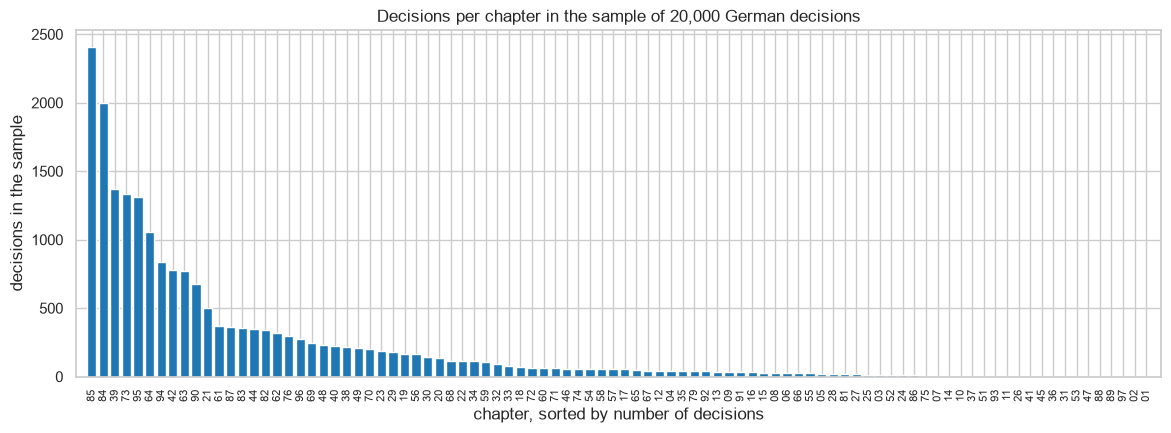

In [7]:
# One bar per chapter, in the order of the counts; the chapter codes are the tick labels
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(decisions_per_chapter.index, decisions_per_chapter.to_numpy(), color="tab:blue")
ax.set_xlabel("chapter, sorted by number of decisions")
ax.set_ylabel("decisions in the sample")
ax.set_title("Decisions per chapter in the sample of 20,000 German decisions")
# Small rotated labels, so all 92 chapter codes fit
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.margins(x=0.01)
plt.show()

**What do you see?** A few chapters hold most decisions: chapter 85 has 2,410 of the 20,000, chapter 84 has 1,998 and chapter 39 has 1,367. To the right, a long tail of chapters has only a handful each, and the smallest has a single decision. Accuracy is dominated by the large chapters, so we also report macro-F1, which gives every chapter the same weight.

## 4 Split the data

We hold back a quarter of the decisions as the **test set** and use it once, at the end. `random_state=0` makes the split the same every time. We do not stratify by chapter, because a few chapters have only one decision in the sample, and stratifying needs at least two per class.

In [8]:
from sklearn.model_selection import train_test_split

# Keep 25% of the decisions as the test set; the texts and their chapters are split together
train_text, test_text, train_chapter, test_chapter = train_test_split(
    german_decisions["description"], german_decisions["chapter"], test_size=0.25, random_state=0)
print(len(train_text), "training decisions,", len(test_text), "test decisions")

15000 training decisions, 5000 test decisions


## 5 Process the data

A model needs numbers, so `TfidfVectorizer` turns each description into a long row of word weights. It learns the vocabulary from the training texts only. TF-IDF gives a word a high weight when it is frequent in this description but rare in the others.

- `sublinear_tf=True` uses 1 + log(count), so a word repeated ten times does not count ten times as much;
- `min_df=2` keeps only words that appear in at least two training descriptions.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(sublinear_tf=True, min_df=2)
# fit_transform learns the vocabulary and the word rarities from the training texts and returns a sparse matrix
train_matrix = tfidf.fit_transform(train_text)
# nnz is the number of non-zero entries; divided by all entries it gives the share that is not 0
share_non_zero = train_matrix.nnz / (train_matrix.shape[0] * train_matrix.shape[1])
print(train_matrix.shape, "; share of non-zero entries:", round(share_non_zero, 4))

(15000, 29840) ; share of non-zero entries: 0.0024


Each description becomes a row with tens of thousands of columns, almost all of them 0: a **sparse matrix**, which stores only the non-zero values. All input is one column of text, so no `ColumnTransformer` is needed.

What does TF-IDF change? For the first example description of step 3, the plot shows every word of the vocabulary that it contains: on the left how often the word occurs (`CountVectorizer` with the same vocabulary), on the right its TF-IDF weight.

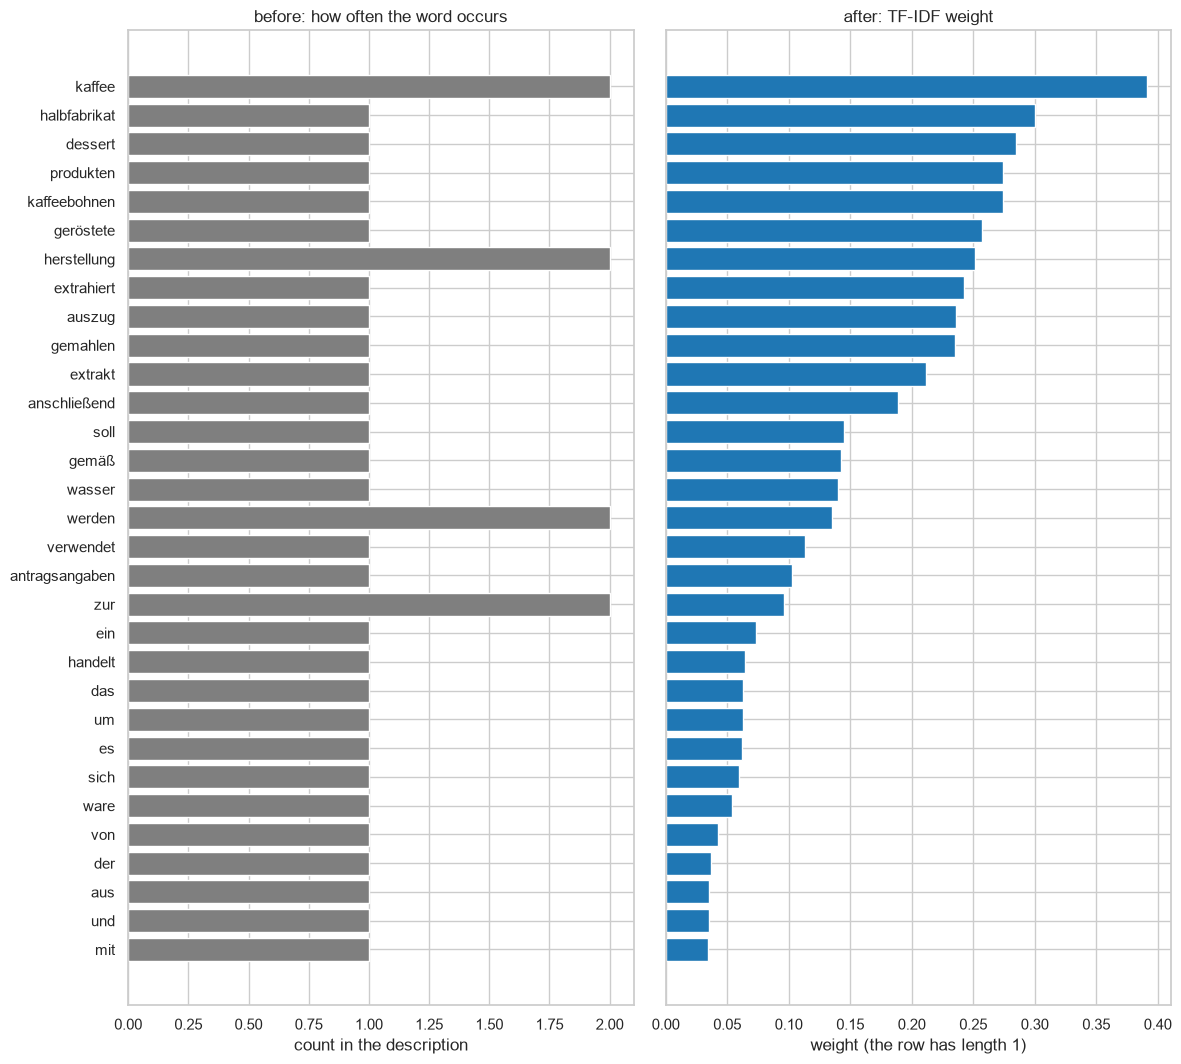

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

example_text = example_decisions["description"].iloc[0]
# A counter with the same vocabulary as tfidf, so both give one value per word
counter = CountVectorizer(vocabulary=tfidf.vocabulary_)
# The words of the example as a table: raw count and TF-IDF weight; toarray() turns the sparse row into a plain array
word_values = pd.DataFrame({
    "count": counter.transform([example_text]).toarray()[0],
    "TF-IDF weight": tfidf.transform([example_text]).toarray()[0],
}, index=tfidf.get_feature_names_out())
# Keep the words that occur in the example, sorted by their TF-IDF weight
example_words = word_values[word_values["count"] > 0].sort_values("TF-IDF weight")

# Left: the raw counts; right: the TF-IDF weights, the same words in the same order
fig, (ax_count, ax_weight) = plt.subplots(1, 2, figsize=(12, 0.3 * len(example_words) + 1.5), sharey=True)
ax_count.barh(example_words.index, example_words["count"], color="tab:gray")
ax_count.set_title("before: how often the word occurs")
ax_count.set_xlabel("count in the description")
ax_weight.barh(example_words.index, example_words["TF-IDF weight"], color="tab:blue")
ax_weight.set_title("after: TF-IDF weight")
ax_weight.set_xlabel("weight (the row has length 1)")
plt.tight_layout()
plt.show()

**What do you see?** On the left, almost every word occurs once, so the counts cannot tell the important words from the filler. On the right, TF-IDF ranks them: *kaffee* gets the largest weight (about 0.39: it occurs twice and is rare in other descriptions), followed by *halbfabrikat* (semi-finished product) and *dessert*. Words that occur in almost every description, such as *mit*, *und*, *aus* and *der*, get the smallest weights, and so do *werden* and *zur*, although they occur twice. The squared weights of one row add up to 1, so long and short descriptions are on the same scale.

## 6 Run the pipeline

We start with the most common pipeline for text, score it, and then improve it one step at a time: TF-IDF with logistic regression, the same pipeline tuned with a grid search, and then a second model, naive Bayes, also tuned. The five decisions of the two kinds of model:

| Decision | TF-IDF and logistic regression | TF-IDF and complement naive Bayes |
|---|---|---|
| Data | the training descriptions as TF-IDF rows X, the chapter y | the same |
| Model | a linear model with one weight per word and chapter; softmax turns the chapter scores into probabilities | one weight per word and chapter, learned from how often the word occurs in all *other* chapters; the chapter with the best sum wins |
| Loss function | log loss plus an L2 penalty; `C` is the inverse of its strength | none minimized step by step: the weights are smoothed word shares, `alpha` is the smoothing |
| Optimizer | L-BFGS, a variant of gradient descent (`solver="lbfgs"`) | none: one pass of counting over the training rows |
| Evaluation | accuracy and macro-F1 on the test set; `GridSearchCV` chooses `C`, the n-gram range and `min_df` | the same; `GridSearchCV` chooses `alpha` and the n-gram range |

### 6.1 TF-IDF and logistic regression

`LogisticRegression` learns one weight per word and chapter and predicts the chapter with the highest score. A `Pipeline` chains the vectorizer of step 5 and the model, so `fit` learns the vocabulary and the weights from the training texts only, and `predict` applies both to new texts. `LogisticRegression` is **regularised**: the loss has an extra L2 penalty that grows with the size of the weights, so a large weight must earn its place. Its strength is set by `C`, the *inverse* of the strength (a small `C` is a strong penalty). We keep the default `C=1`. `max_iter=1000` gives the optimizer enough steps to finish.

We then score the pipeline on the test set with two measures from `sklearn.metrics`, which compare the predicted chapters with the true ones:

- **Accuracy** (`accuracy_score`): the share of test decisions with the right chapter.
- **Macro-F1** (`f1_score(..., average="macro")`): the F1 score of every chapter, averaged with equal weight, so a chapter with 5 decisions counts as much as one with 600. `zero_division=0` scores a chapter that is never predicted as 0 instead of warning.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline

# A Pipeline runs its steps in order: first TF-IDF, then the model
logistic_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=2)),
    ("logistic", LogisticRegression(max_iter=1000)),
])
# fit learns the vocabulary and the weights from the training texts
logistic_pipeline.fit(train_text, train_chapter)

# Predict a chapter for every test description
# y_predicted_logistic: the predicted chapter of every test description
y_predicted_logistic = logistic_pipeline.predict(test_text)
# Each metric compares the true chapters with the predicted ones; the dictionary is kept for the table of step 7
logistic_scores = {
    "model": "logistic regression",
    "accuracy": accuracy_score(test_chapter, y_predicted_logistic),
    "macro-F1": f1_score(test_chapter, y_predicted_logistic, average="macro", zero_division=0),
}
print(f"logistic regression: accuracy {logistic_scores['accuracy']:.3f}, macro-F1 {logistic_scores['macro-F1']:.3f}")

logistic regression: accuracy 0.944, macro-F1 0.661


**What do you see?** With the default penalty `C=1`, logistic regression gives the right chapter to 94.4% of the 5,000 test descriptions, but its macro-F1 is only 0.661: the large chapters are mostly right, many small chapters are not. A strong penalty keeps the weights of rare words small, and rare words are what small chapters have.

### 6.2 Tune the pipeline with a grid search

Three settings are **hyperparameters**: we choose them, the model does not learn them. `GridSearchCV` tries every combination in a grid and keeps the best one. It scores each combination on parts of the training set only, so the test set stays unseen until we score the winner.

- `logistic__C`: the strength of the regularisation, `C` of the step named `logistic`. `C` is the inverse of the strength: a large `C` is a weak penalty, which lets rare but telling words get large weights.
- `tfidf__ngram_range`: `(1, 1)` uses single words, `(1, 2)` also pairs of neighbouring words, such as *aus Kunststoff* (made of plastic).
- `tfidf__min_df`: keep words that occur in at least 2 or at least 5 training descriptions.
- `cv=KFold(3, shuffle=True, random_state=0)` splits the training set into 3 parts, each used once for scoring. The default split would stratify by chapter and warns when a chapter has fewer than 3 decisions.
- `scoring=make_scorer(f1_score, average="macro", zero_division=0)` chooses by macro-F1, our main score. `n_jobs=4` runs four fits in parallel on four processor cores.

The grid has 4 × 2 × 2 = 16 combinations, so the search fits 48 pipelines.

In [12]:
import warnings

from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV, KFold

# joblib, which runs the parallel fits, may restart an idle worker and warn about it; the results are not affected
warnings.filterwarnings("ignore", message="A worker stopped while some jobs were given to the executor")

# The scorer the search maximizes: macro-F1, a chapter never predicted counts as 0
macro_f1_scorer = make_scorer(f1_score, average="macro", zero_division=0)
# Three parts of the training set, shuffled with a fixed seed
three_folds = KFold(3, shuffle=True, random_state=0)
logistic_grid = {
    "logistic__C": [1, 10, 100, 1000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
}
logistic_search = GridSearchCV(logistic_pipeline, logistic_grid, scoring=macro_f1_scorer, cv=three_folds, n_jobs=4)
# fit runs the whole search, then refits the best pipeline on all training decisions
logistic_search.fit(train_text, train_chapter)
print("chosen:", logistic_search.best_params_)
# best_estimator_ is the refitted best pipeline; only now do we score it on the test set
y_predicted_tuned_logistic = logistic_search.best_estimator_.predict(test_text)
tuned_logistic_scores = {
    "model": "logistic regression, tuned",
    "accuracy": accuracy_score(test_chapter, y_predicted_tuned_logistic),
    "macro-F1": f1_score(test_chapter, y_predicted_tuned_logistic, average="macro", zero_division=0),
}
print(f"logistic regression, tuned: accuracy {tuned_logistic_scores['accuracy']:.3f}, "
      f"macro-F1 {tuned_logistic_scores['macro-F1']:.3f}")

chosen: {'logistic__C': 1000, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 1)}
logistic regression, tuned: accuracy 0.975, macro-F1 0.829


`cv_results_` holds the mean macro-F1 of every combination on the training parts. A heatmap shows all 16 at once: one panel per n-gram range, `C` across, `min_df` down.

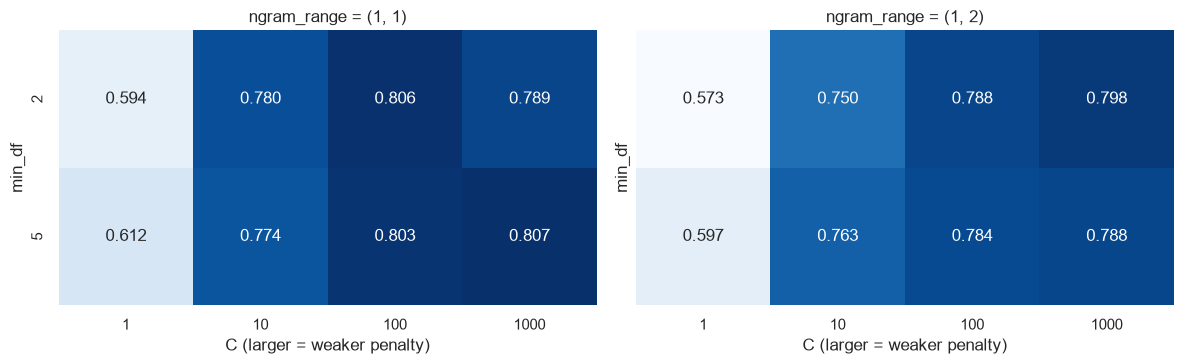

In [13]:
# One row per combination: its settings and its mean macro-F1 over the 3 parts
search_results = pd.DataFrame(logistic_search.cv_results_["params"])
search_results["macro-F1"] = logistic_search.cv_results_["mean_test_score"]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, ngram_range in zip(axes, [(1, 1), (1, 2)]):
    # pivot puts min_df in the rows and C in the columns
    one_range = search_results[search_results["tfidf__ngram_range"] == ngram_range]
    grid_table = one_range.pivot(index="tfidf__min_df", columns="logistic__C", values="macro-F1")
    # vmin and vmax give both panels the same colour scale
    sns.heatmap(grid_table, annot=True, fmt=".3f", cmap="Blues", cbar=False, ax=ax,
                vmin=search_results["macro-F1"].min(), vmax=search_results["macro-F1"].max())
    ax.set_title(f"ngram_range = {ngram_range}")
    ax.set_xlabel("C (larger = weaker penalty)")
    ax.set_ylabel("min_df")
plt.tight_layout()
plt.show()

**What do you see?** The penalty matters most. With `C=1` the macro-F1 on the training parts is 0.57 to 0.61; with `C=100` or `C=1000` it is 0.78 to 0.81. Word pairs help in only one cell (`C=1000`, `min_df=2`: 0.798 against 0.789), and `min_df` changes little. The best combination is single words, `min_df=5` and `C=1000` (0.807), narrowly ahead of `C=100` with `min_df=2` (0.806). `C=1000` is the largest value in the grid, so an even weaker penalty might score a little higher, but the top cells differ only in the third decimal. On the test set, the tuned pipeline reaches an accuracy of 0.975 and a macro-F1 of 0.829, up from 0.944 and 0.661.

### 6.3 A second model: naive Bayes

Naive Bayes is the classic fast model for text. `ComplementNB` is the variant made for many unequal classes (Rennie and colleagues, MIT, 2003): for each chapter it counts how often each word occurs in the descriptions of all *other* chapters, and a word that is rare elsewhere speaks for the chapter. It learns in one pass, with no optimizer. The grid tries three values of the smoothing `alpha` (how much weight unseen words get) and the two n-gram ranges, six settings in all.

In [14]:
from sklearn.naive_bayes import ComplementNB

# The same TF-IDF step, then complement naive Bayes
bayes_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=2)),
    ("bayes", ComplementNB()),
])
# 3 smoothing values × 2 n-gram ranges = 6 settings to try
bayes_grid = {"bayes__alpha": [0.01, 0.1, 1], "tfidf__ngram_range": [(1, 1), (1, 2)]}
bayes_search = GridSearchCV(bayes_pipeline, bayes_grid, scoring=macro_f1_scorer, cv=three_folds, n_jobs=4)
bayes_search.fit(train_text, train_chapter)
print("chosen:", bayes_search.best_params_)
# Score the refitted best pipeline on the test set, as in 6.1
y_predicted_bayes = bayes_search.best_estimator_.predict(test_text)
bayes_scores = {
    "model": "naive Bayes, tuned",
    "accuracy": accuracy_score(test_chapter, y_predicted_bayes),
    "macro-F1": f1_score(test_chapter, y_predicted_bayes, average="macro", zero_division=0),
}
print(f"naive Bayes, tuned: accuracy {bayes_scores['accuracy']:.3f}, macro-F1 {bayes_scores['macro-F1']:.3f}")

chosen: {'bayes__alpha': 0.01, 'tfidf__ngram_range': (1, 2)}


naive Bayes, tuned: accuracy 0.965, macro-F1 0.852


**What do you see?** The grid chose the smallest smoothing, `alpha = 0.01`, and word pairs. Naive Bayes gives the right chapter to 96.5% of the test descriptions, fewer than tuned logistic regression (97.5%), but its macro-F1 is higher: 0.852 against 0.829. So naive Bayes does better on the small chapters and worse on the large ones. Step 7 checks whether these gaps are larger than chance.

### 6.4 What did the chosen model learn?

Tuned logistic regression has the highest accuracy and tuned naive Bayes the highest macro-F1; step 7 checks whether these gaps are real. We look closer at logistic regression: it gives the most requests the right chapter, and its weight for each word can be read directly.

The figures and tables below name each chapter. A lookup from code to name, read from the English tariff, makes them readable: a chapter's line there has a goods code of two digits followed by eight zeros, such as `8500000000`.

In [15]:
# Read the English tariff; dtype=str keeps the leading zeros of the codes
nomenclature = pd.read_excel("case-study/final-challenge/data/nomenclature/Nomenclature EN.xlsx", dtype=str)
# A chapter line has a goods code of two digits followed by eight zeros
is_chapter_line = nomenclature["Goods code"].str[2:10] == "00000000"
chapter_lines = nomenclature[is_chapter_line]
# A Series from chapter code to name; capitalize() turns the capitals of the tariff into normal writing
chapter_names = pd.Series(chapter_lines["Description"].str.capitalize().to_numpy(), index=chapter_lines["Goods code"].str[:2])
print(len(chapter_names), "chapter names; chapter 85:", chapter_names["85"])

98 chapter names; chapter 85: Electrical machinery and equipment and parts thereof; sound recorders and reproducers, television image and sound recorders and reproducers, and parts and accessories of such articles


Logistic regression's `coef_` holds one weight per chapter and word (or word pair); `get_feature_names_out()` gives the words in the same order. For the four largest chapters of the training set, the bars show the ten words with the largest weights: the words that push a description towards that chapter.

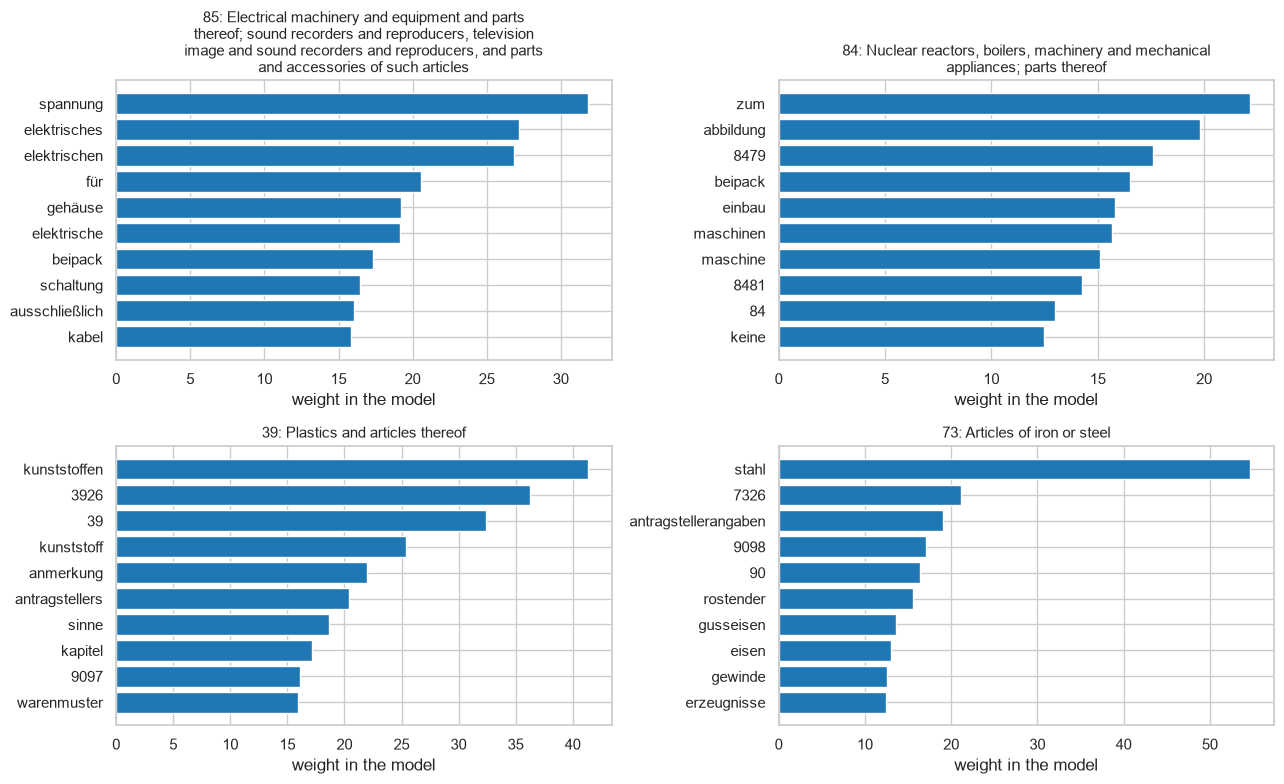

In [16]:
chosen_pipeline = logistic_search.best_estimator_
# The vocabulary in column order, and the weight table: one row per chapter, one column per word
vocabulary = chosen_pipeline["tfidf"].get_feature_names_out()
word_weights = pd.DataFrame(chosen_pipeline["logistic"].coef_, index=chosen_pipeline.classes_, columns=vocabulary)
# The four chapters with the most training decisions
largest_chapters = train_chapter.value_counts().index[:4]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, chapter in zip(axes.flat, largest_chapters):
    # nlargest(10) keeps the ten highest weights of this chapter; sort_values puts the largest on top
    top_words = word_weights.loc[chapter].nlargest(10).sort_values()
    ax.barh(top_words.index, top_words.to_numpy(), color="tab:blue")
    # The chapter name, wrapped so it fits above the panel
    ax.set_title(textwrap.fill(f"{chapter}: {chapter_names[chapter]}", 55), fontsize=11)
    ax.set_xlabel("weight in the model")
plt.tight_layout()
plt.show()

**What do you see?** Many top words are what one expects: *spannung* (voltage), *elektrisches* and *schaltung* (circuit) for chapter 85, *maschine* and *maschinen* for 84, *kunststoff* (plastic) for 39, and *stahl* (steel), *rostender* (stainless) and *gusseisen* (cast iron) for 73. Some are numbers, such as *3926*, *8479*, *7326* and *39*: descriptions sometimes quote a heading or a chapter of the tariff, for example in the customs' finding (*im Sinne der Anmerkung … zu Kapitel 39*). A description that names its own heading is an easy case, so descriptions without such numbers may be harder than the scores suggest. Other top words belong to the form of the text rather than the product, such as *beipack* (enclosure), *abbildung* (picture) and *antragstellerangaben* (the applicant's statement).

The **confusion matrix** of the predictions of 6.2 counts every combination of true and predicted chapter: rows are the true chapters, columns the predicted ones, in the order of the chapter codes. `normalize="true"` divides each row by its total, so a cell is the share of a chapter's test decisions that went to that column, and the diagonal is the recall of each chapter. `sns.heatmap` draws the table as coloured cells, one row and one column for every chapter that occurs in the test set.

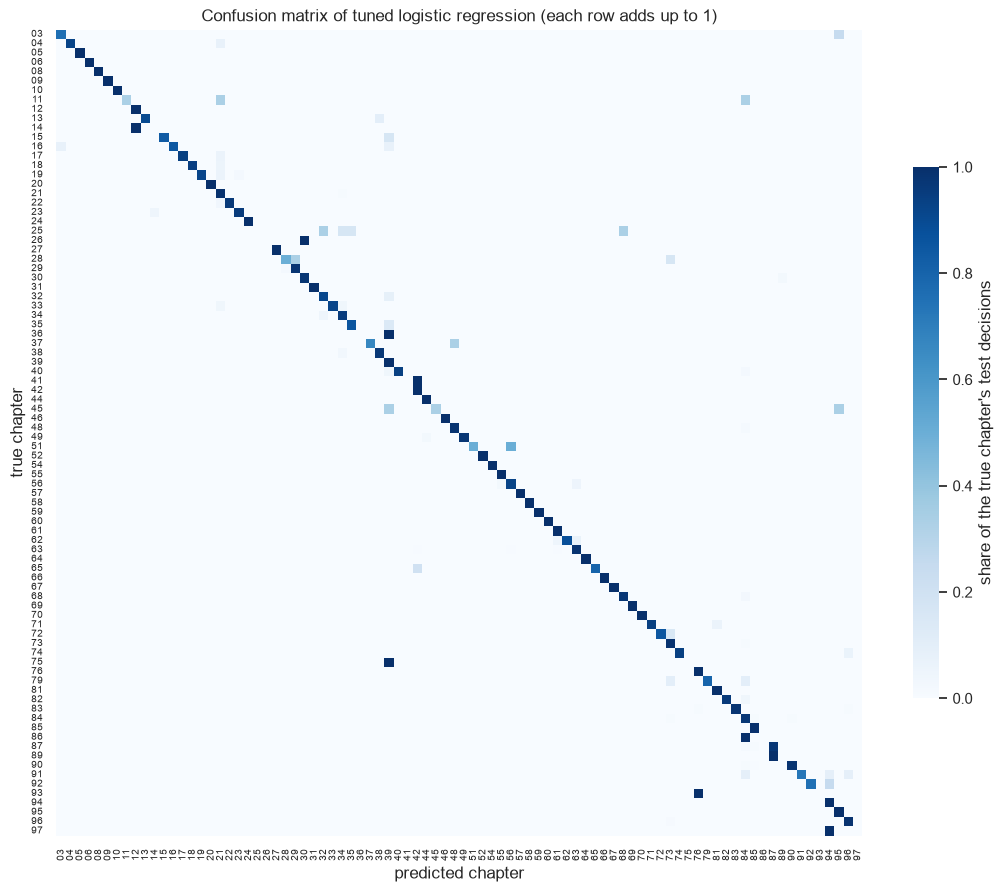

In [17]:
from sklearn.metrics import confusion_matrix

# Every chapter that occurs in the test set as a true or a predicted chapter, in code order
chapter_order = sorted(set(test_chapter) | set(y_predicted_tuned_logistic))
# Each row divided by its total: the share of a true chapter that went to each predicted chapter
confusion_shares = confusion_matrix(test_chapter, y_predicted_tuned_logistic, labels=chapter_order, normalize="true")

fig, ax = plt.subplots(figsize=(13, 11.5))
# No numbers in the cells (there are too many); the colour bar reads the shares
sns.heatmap(confusion_shares, cmap="Blues", vmin=0, vmax=1, xticklabels=chapter_order, yticklabels=chapter_order,
            square=True, cbar_kws={"label": "share of the true chapter's test decisions", "shrink": 0.6}, ax=ax)
ax.set_xlabel("predicted chapter")
ax.set_ylabel("true chapter")
ax.set_title("Confusion matrix of tuned logistic regression (each row adds up to 1)")
ax.tick_params(labelsize=7)
plt.show()

**What do you see?** Almost all the colour lies on the diagonal: most chapters are recognized. The dark cells off the diagonal sit in small chapters, where a single decision is the whole row. For example, the test decision of chapter 75 (nickel) went to 39 (plastics), and that of chapter 41 (raw hides and leather) went to 42 (articles of leather). The errors tend to go to related chapters that use similar words.

The heatmap shows where errors happen but not how many. The table lists every pair of chapters that the model confused at least 3 times on the test set, with both names. `pd.crosstab` counts the pairs.

In [18]:
# A table of counts: one row per true chapter, one column per predicted chapter
pair_counts = pd.crosstab(test_chapter.to_numpy(), y_predicted_tuned_logistic, rownames=["true"], colnames=["predicted"])
# stack() makes one row per (true, predicted) pair; keep the wrong pairs with at least 3 decisions
pair_counts = pair_counts.stack().rename("test decisions").reset_index()
frequent_confusions = pair_counts[(pair_counts["true"] != pair_counts["predicted"]) & (pair_counts["test decisions"] >= 3)]
frequent_confusions = frequent_confusions.sort_values("test decisions", ascending=False)
# Add the chapter names, so the pairs can be read without the tariff
frequent_confusions["true chapter"] = frequent_confusions["true"].map(chapter_names)
frequent_confusions["predicted chapter"] = frequent_confusions["predicted"].map(chapter_names)
with pd.option_context("display.max_colwidth", None):
    display(frequent_confusions.set_index(["true", "predicted"]))

test decisions  \
true predicted                   
62   63                      6   
84   85                      5   
62   61                      4   
84   73                      4   
     90                      4   
19   21                      3   
72   73                      3   
73   84                      3   
82   84                      3   
85   84                      3   
86   84                      3   

                                                                                                                                                                                                                         true chapter  \
true predicted                                                                                                                                                                                                                          
62   63                                                                                                                                                        Articles of apparel and clothing accessories, not knitted or crocheted   
84   85                                                                                                                                                 Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof   
62   61                                                                                                                                                        Articles of apparel and clothing accessories, not knitted or crocheted   
84   73                                                                                                                                                 Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof   
     90                                                                                                                                                 Nuclear reactors, boilers, machinery and mechanical appliances; parts thereof   
19   21                                                                                                                                                         Preparations of cereals, flour, starch or milk; pastrycooks' products   
72   73                                                                                                                                                                                                                Iron and steel   
73   84                                                                                                                                                                                                     Articles of iron or steel   
82   84                                                                                                                                      Tools, implements, cutlery, spoons and forks, of base metal; parts thereof of base metal   
85   84                                       Electrical machinery and equipment and parts thereof; sound recorders and reproducers, television image and sound recorders and reproducers, and parts and accessories of such articles   
86   84         Railway or tramway locomotives, rolling stock and parts thereof; railway or tramway track fixtures and fittings and parts thereof; mechanical (including electromechanical) traffic signalling equipment of all kinds   

                                                                                                                                                                                      predicted chapter  
true predicted                                                                                                                                                                                           
62   63                                                                                                             Other made-up textile a

**What do you see?** Eleven pairs occur three times or more, and eight of them involve the machinery chapters 84 and 85: machines taken for electrical equipment (5 times) and back (3 times), machines taken for articles of iron or steel (73) or for instruments (90), and articles of iron or steel, tools (82) and railway equipment (86) taken for machines. Clothing is the other group: apparel that is not knitted (62) taken for other textile articles (63) six times and for knitted apparel (61) four times. These are borders in the tariff itself, where officers also need the rules and notes, not only the words.

Every chapter has its own F1 score. `classification_report(..., output_dict=True)` returns the precision, recall, F1 and number of test decisions (`support`) of every chapter as a dictionary. The plot shows the F1 of each chapter against its number of test decisions. It is interactive (plotly): hold the mouse over a point to read the chapter, its name and its scores.

In [19]:
import plotly.express as px
from sklearn.metrics import classification_report

report = classification_report(test_chapter, y_predicted_tuned_logistic, output_dict=True, zero_division=0)
# One row per chapter; drop the three summary rows that the report adds
chapter_scores = pd.DataFrame(report).T.drop(index=["accuracy", "macro avg", "weighted avg"])
chapter_scores.index.name = "chapter"
chapter_scores = chapter_scores.reset_index()
chapter_scores["name"] = chapter_scores["chapter"].map(chapter_names)
# Chapters with no test decisions have no F1 to show
chapter_scores = chapter_scores[chapter_scores["support"] > 0]

# A scatter plot with a logarithmic x-axis, so the small chapters do not pile up at the left;
# hover_data lists what appears when the mouse is over a point
figure = px.scatter(chapter_scores, x="support", y="f1-score", log_x=True,
                    hover_name="chapter", hover_data={"name": True, "precision": ":.2f", "recall": ":.2f"},
                    labels={"support": "test decisions of the chapter (log scale)", "f1-score": "F1 of the chapter"},
                    title="F1 of every chapter against its size, tuned logistic regression",
                    width=850, height=450, template="plotly_white")
# Save the figure in two forms: plotly's own format (JupyterLab, VS Code) and HTML that loads plotly from the web
figure.show(renderer="plotly_mimetype+notebook_connected")

**What do you see?** Each point is one of the 86 chapters with test decisions. Every chapter with more than 20 test decisions has an F1 of 0.89 or higher. The small chapters spread from 0 to 1: the 24 chapters with 5 test decisions or fewer have a mean F1 of 0.53, and 10 chapters, each with at most 6 test decisions, have an F1 of 0. These small chapters pull macro-F1 (0.829) far below accuracy (0.975).

Finally, a few errors read in full. We print the three shortest test descriptions that the model assigns to a wrong chapter, with the true and the predicted chapter.

In [20]:
# True and predicted chapter of every test decision, with the text
test_decisions = pd.DataFrame({"description": test_text, "true": test_chapter, "predicted": y_predicted_tuned_logistic})
wrong_decisions = test_decisions[test_decisions["true"] != test_decisions["predicted"]]
# The three shortest wrong ones, so they can be read in full
shortest_wrong = wrong_decisions.loc[wrong_decisions["description"].str.len().sort_values().index[:3]]
for _, decision in shortest_wrong.iterrows():
    print(f"true {decision['true']} ({chapter_names[decision['true']]})")
    print(f"predicted {decision['predicted']} ({chapter_names[decision['predicted']]})")
    print(textwrap.fill(decision["description"], 100), end="\n\n")

true 25 (Salt; sulphur; earths and stone; plastering materials, lime and cement)
predicted 32 (Tanning or dyeing extracts; tannins and their derivatives; dyes, pigments and other colouring matter; paints and varnishes; putty and other mastics; inks)
Angaben: Kaolin in Pulverform; cremefarben; geruchslos; Verwendung zur Herstellung von
Dieselpartikelfiltern; CAS Nr. 1332-58-7.  Befund: Kaolin.

true 40 (Rubber and articles thereof)
predicted 39 (Plastics and articles thereof)
Angaben des Antragstellers: Styrol-Blockcopolymer in Form eines weißen, grobkörnigen Pulvers
Befund: Anderer synthetischer Kautschuk in Primärform im Sinne der Unterposition

true 19 (Preparations of cereals, flour, starch or milk; pastrycooks' products)
predicted 23 (Residues and waste from the food industries; prepared animal fodder)
Reispapier  Quadratische, weißliche, dünne, brüchige Reispapierplatten (16 cm Kantenlänge), für den
Einzelverkauf aufgemacht à 37 - 41 Stück.   Getrocknete Teigblätter aus Mehl oder 

**What do you see?** The three errors are near misses that a reader without the tariff would make too. Kaolin, a clay (chapter 25, earths and stone), was taken for a colouring matter (32). A styrene block copolymer is a synthetic rubber (40) according to the customs' finding, but the model chose plastics (39). Rice paper made from flour or starch (19) went to food residues and animal fodder (23). The second text even names the answer, *synthetischer Kautschuk* (synthetic rubber), yet the words that point to plastics win.

## 7 Report the results

One table puts the three models side by side, in the order we built them. Then we ask how sure these numbers are.

In [21]:
# One row per model, built from the score dictionaries of 6.1, 6.2 and 6.3
test_results = pd.DataFrame([logistic_scores, tuned_logistic_scores, bayes_scores]).set_index("model").round(3)
test_results

,accuracy,macro-F1
model,,
logistic regression,0.944,0.661
"logistic regression, tuned",0.975,0.829
"naive Bayes, tuned",0.965,0.852


### 7.1 How sure is each score?

The test set is one sample of 5,000 decisions. Another sample would give slightly different scores. A **95% confidence interval** shows how far a score could move for that reason: over many test sets, 95 of 100 such intervals contain the model's true score.

**Accuracy is a share**: right chapters out of all test decisions. For a share we use the **Wilson interval**, `proportion_confint(count, total, method="wilson")` from statsmodels. It stays between 0 and 1 even when the share is close to 1, where the usual formula, the share plus or minus 1.96 standard errors, can pass 1. With 92 chapters and only a few test decisions in many of them, we do not compute an interval for the recall of each chapter.

In [22]:
from statsmodels.stats.proportion import proportion_confint

# The test predictions of 6.1, 6.2 and 6.3, by model: the intervals never refit a model
y_predicted_by_model = {
    "logistic regression": y_predicted_logistic,
    "logistic regression, tuned": y_predicted_tuned_logistic,
    "naive Bayes, tuned": y_predicted_bayes,
}

# For each model: how many test decisions it gets right, and the Wilson interval of that share
true_chapters = test_chapter.to_numpy()
n_test_rows = len(true_chapters)
accuracy_rows = []
for model_name, y_predicted in y_predicted_by_model.items():
    n_right = int((y_predicted == true_chapters).sum())
    lower, upper = proportion_confint(n_right, n_test_rows, method="wilson")
    accuracy_rows.append({"model": model_name, "right": n_right, "wrong": n_test_rows - n_right,
                          "accuracy": n_right / n_test_rows, "95% CI from": lower, "95% CI to": upper})
accuracy_intervals = pd.DataFrame(accuracy_rows).set_index("model").round(3)
accuracy_intervals

,right,wrong,accuracy,95% CI from,95% CI to
model,,,,,
logistic regression,4719,281,0.944,0.937,0.950
"logistic regression, tuned",4877,123,0.975,0.971,0.979
"naive Bayes, tuned",4825,175,0.965,0.960,0.970


**What do you see?** Tuned logistic regression is right for 4,877 of the 5,000 test decisions: accuracy 0.975, 95% Wilson interval 0.971 to 0.979. Each model makes more than 100 errors, and with 5,000 decisions every interval is narrow, at most about ±0.007. The intervals of the three models do not overlap.

**Macro-F1 has no simple formula** for its interval, so we use the **bootstrap**. The fitted models stay fixed; only the test rows are drawn again:

1. Draw 5,000 test rows **with replacement**: some decisions appear twice, some not at all.
2. Compute the macro-F1 on these rows.
3. Repeat 1,000 times. The middle 95% of the 1,000 scores, from the 2.5th to the 97.5th percentile, is the interval.

`rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array.

**A trap with many small classes.** Macro-F1 averages over the chapters that occur in the rows. A chapter with a single test decision is missing from about 37 of 100 plain resamples (the chance that one row is never drawn in 5,000 draws, (1 − 1/5000)^5000 ≈ 0.37). Then its F1 drops out of the average. So we also draw the rows **within each chapter**: every chapter keeps its number of test decisions, and only which of its decisions are drawn changes (a *stratified* bootstrap). The cell computes both and puts them side by side. The loop computes 6,000 macro-F1 scores and takes a little while.

In [23]:
rng = np.random.default_rng(0)
n_resamples = 1000
# Plain bootstrap: 1,000 resamples of all test rows; each row of the array holds the positions of one resample
plain_rows = rng.integers(0, n_test_rows, size=(n_resamples, n_test_rows))

# Stratified bootstrap: the positions of the test decisions of each chapter ...
rows_per_chapter = [np.flatnonzero(true_chapters == chapter) for chapter in np.unique(true_chapters)]
# ... and for each resample, as many draws within each chapter as it has decisions; concatenate joins them
stratified_rows = np.array([
    np.concatenate([rows[rng.integers(0, len(rows), size=len(rows))] for rows in rows_per_chapter])
    for _ in range(n_resamples)])

# The macro-F1 of every model on both kinds of resample, and the two intervals
plain_macro_f1, stratified_macro_f1 = {}, {}
interval_rows = []
for model_name, y_predicted in y_predicted_by_model.items():
    # The macro-F1 of the fixed predictions on every resample: 1,000 values for each kind of bootstrap
    plain_macro_f1[model_name] = np.array([
        f1_score(true_chapters[rows], y_predicted[rows], average="macro", zero_division=0) for rows in plain_rows])
    stratified_macro_f1[model_name] = np.array([
        f1_score(true_chapters[rows], y_predicted[rows], average="macro", zero_division=0) for rows in stratified_rows])
    # The interval: the 2.5th and the 97.5th percentile of the 1,000 values
    plain_lower, plain_upper = np.percentile(plain_macro_f1[model_name], [2.5, 97.5])
    lower, upper = np.percentile(stratified_macro_f1[model_name], [2.5, 97.5])
    interval_rows.append({"model": model_name, "macro-F1": test_results.loc[model_name, "macro-F1"],
                          "plain: from": plain_lower, "plain: to": plain_upper,
                          "within chapters: from": lower, "within chapters: to": upper})
macro_f1_intervals = pd.DataFrame(interval_rows).set_index("model").round(3)
macro_f1_intervals

,macro-F1,plain: from,plain: to,within chapters: from,within chapters: to
model,,,,,
logistic regression,0.661,0.656,0.724,0.642,0.672
"logistic regression, tuned",0.829,0.814,0.880,0.808,0.842
"naive Bayes, tuned",0.852,0.827,0.887,0.831,0.865


**What do you see?** The plain bootstrap gives intervals that are not centred on the score: for untuned logistic regression, the score 0.661 lies at the lower end of its interval, 0.656 to 0.724. This is the trap: resamples that miss the rare chapters with an F1 of 0 score higher. Within chapters, every interval is centred on its score: 0.808 to 0.842 for tuned logistic regression and 0.831 to 0.865 for naive Bayes. We use these from here on. They answer a slightly narrower question: how far would macro-F1 move with other decisions from the same chapters, in the same numbers? The intervals of tuned logistic regression and naive Bayes overlap.

### 7.2 Is one model really better? The interval of the difference

To compare two models, we do not compare their two intervals. A comparison of two classmates shows why.

> Anna and Ben take the same exam every year, and the exam is harder in some years than in others. Anna's scores range from 70 to 90, and Ben's from 75 to 95, so the ranges overlap. But in every year, on the same exam, Ben scores about 5 points more than Anna. Is Ben better? Yes. The overlap only shows that the exams vary in difficulty. To compare them, you compare them on the same exam, which is the difference.

Our models are in the same situation: all of them are scored on the **same** 5,000 decisions. A resample that happens to draw many easy descriptions raises every model; one that draws the hard ones of a chapter twice lowers every model. This shared luck makes each interval wide, and it cancels when we subtract one score from the other.

So we compute the **difference** on every resample, with the same rows for both models (the stratified resamples of 7.1): the score of tuned logistic regression minus that of the other model, for accuracy and for macro-F1. The middle 95% of the 1,000 differences is the **95% interval of the difference**:

- the interval lies above 0: tuned logistic regression is better, by about the amount the interval shows; below 0: it is worse;
- the interval contains 0: on this test set we cannot tell the two models apart.

In [24]:
# Accuracy on every stratified resample: the share of right chapters among the drawn rows
stratified_accuracy = {}
for model_name, y_predicted in y_predicted_by_model.items():
    is_right = y_predicted == true_chapters
    stratified_accuracy[model_name] = is_right[stratified_rows].mean(axis=1)

# Each comparison, as (short label, the other model); tuned logistic regression is always the first
chosen_name = "logistic regression, tuned"
comparisons = [("tuned − untuned logistic regression", "logistic regression"),
               ("tuned logistic regression − naive Bayes", "naive Bayes, tuned")]

difference_rows = []
bootstrap_differences = {}
for label, other_name in comparisons:
    for score_name, bootstrap_scores in [("accuracy", stratified_accuracy), ("macro-F1", stratified_macro_f1)]:
        # The same resampled rows for both models, so every difference compares them on the same decisions
        differences = bootstrap_scores[chosen_name] - bootstrap_scores[other_name]
        bootstrap_differences[(label, score_name)] = differences
        lower, upper = np.percentile(differences, [2.5, 97.5])
        difference_rows.append({"comparison": label, "score": score_name,
                                "difference": test_results.loc[chosen_name, score_name] - test_results.loc[other_name, score_name],
                                "95% CI from": lower, "95% CI to": upper})
score_differences = pd.DataFrame(difference_rows).set_index(["comparison", "score"]).round(3)
score_differences

difference  95% CI from  95% CI to
comparison                              score                                       
tuned − untuned logistic regression     accuracy       0.031        0.028      0.036
                                        macro-F1       0.168        0.146      0.189
tuned logistic regression − naive Bayes accuracy       0.010        0.006      0.015
                                        macro-F1      -0.023       -0.045     -0.001

A histogram of the 1,000 differences of each comparison and score shows the same thing as a picture. The solid lines mark the interval, the dashed line a difference of 0, "no difference".

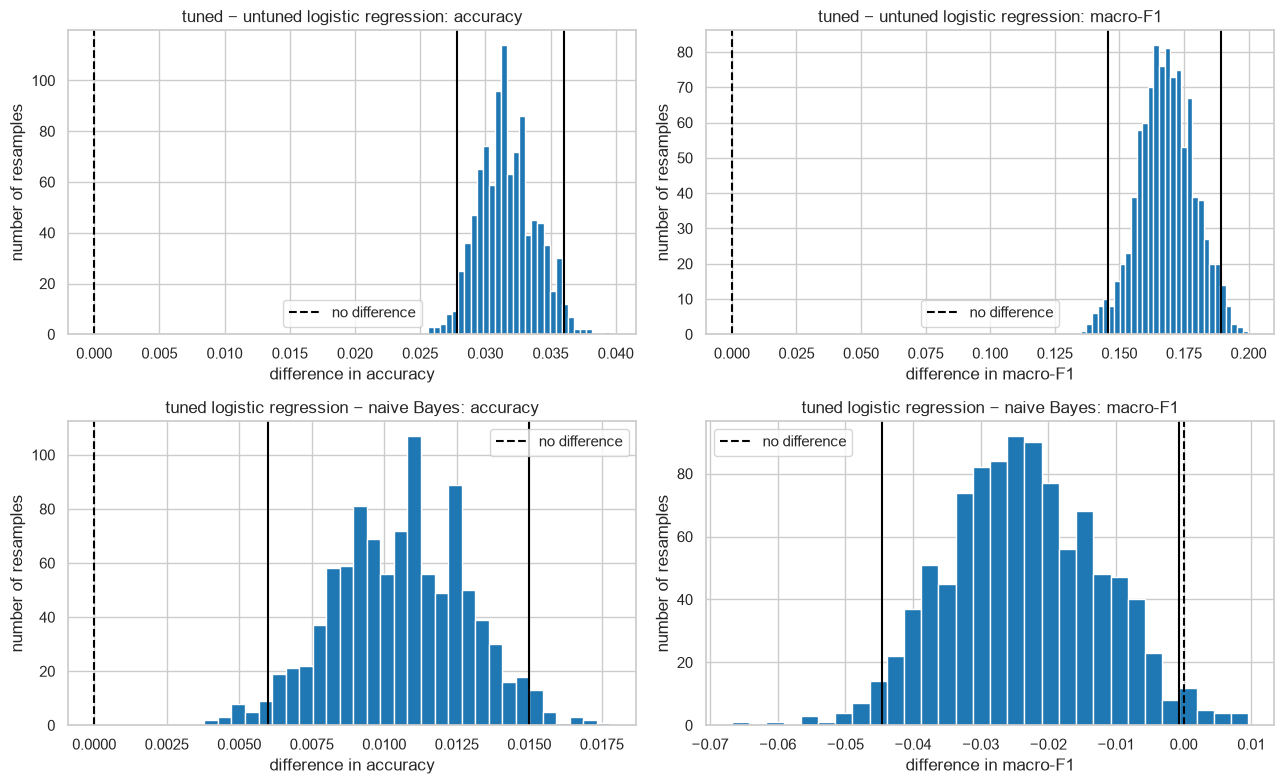

In [25]:
# Rows: the two comparisons; columns: accuracy and macro-F1
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, ((label, score_name), differences) in zip(axes.flat, bootstrap_differences.items()):
    ax.hist(differences, bins=30, color="tab:blue")
    # The 95% interval as two solid lines, the value 0 as a dashed line
    for bound in np.percentile(differences, [2.5, 97.5]):
        ax.axvline(bound, color="black")
    ax.axvline(0, color="black", linestyle="--", label="no difference")
    ax.set_title(f"{label}: {score_name}")
    ax.set_xlabel(f"difference in {score_name}")
    ax.set_ylabel("number of resamples")
    ax.legend()
plt.tight_layout()
plt.show()

**What do you see?** Tuning was worth it: it adds 0.028 to 0.036 to accuracy and 0.146 to 0.189 to macro-F1, far above 0. Between tuned logistic regression and naive Bayes, each model wins on one score. Logistic regression is more accurate, by 0.006 to 0.015. Naive Bayes has the higher macro-F1: the interval of the difference, −0.045 to −0.001, lies below 0. The separate macro-F1 intervals in 7.1 overlap, yet the paired interval does not contain 0: this is the case of Anna and Ben. The margin is thin, though: the upper end is almost 0, so the true gap in macro-F1 could be very small.

**The assumptions behind the intervals.** The usual formula for a share (the share plus or minus 1.96 standard errors) needs about 10 of each outcome, right and wrong; the Wilson interval is safer when one outcome is rare. More important here: the Wilson interval and the bootstrap both treat every test decision as an independent draw. That fails when the same product, or a series of nearly identical products, is described in several decisions: copies can land in both the training and the test set, and the model then partly recognizes texts it has seen. The cell counts the test descriptions that appear word for word in the training set.

In [26]:
# isin checks every test text against the set of training texts
is_seen_text = test_text.isin(set(train_text))
print(f"{is_seen_text.sum()} of {len(test_text)} test descriptions ({is_seen_text.mean():.1%}) appear word for word in the training set")

0 of 5000 test descriptions (0.0%) appear word for word in the training set


**What do you see?** No test description appears word for word in the training set, so exact copies do not inflate the scores. Near copies, such as the same product in another size or colour, are not caught by this check; if there are many, the scores are somewhat optimistic and the intervals somewhat too narrow. The bootstrap within chapters adds one more assumption: the number of test decisions per chapter is fixed.

### 7.3 Use the model on a new input

Imagine the customs office has deployed the chosen model, tuned TF-IDF with logistic regression. A company sends a new description of its product, in German, as in the decisions. The model needs nothing else: the pipeline turns the text into TF-IDF numbers and returns a chapter code. `predict_proba` gives the probability of every chapter; the largest one says how sure the model is. Here are three new descriptions we wrote ourselves: headphones, a T-shirt and biscuits.

In [27]:
# Three new product descriptions, written by us in the style of the decisions
new_descriptions = pd.Series([
    "Kabelloser Kopfhörer mit Bluetooth-Verbindung, Akku und Ladekabel; zum Musikhören mit einem Smartphone.",
    "Damen-T-Shirt aus Gewirke, 100 % Baumwolle, kurze Ärmel, mit Aufdruck.",
    "Kekse mit Schokolade in einer Packung von 200 g; Zutaten: Weizenmehl, Zucker, Kakao, Butter.",
])
# The input, in full
for description in new_descriptions:
    print(description)

Kabelloser Kopfhörer mit Bluetooth-Verbindung, Akku und Ladekabel; zum Musikhören mit einem Smartphone.
Damen-T-Shirt aus Gewirke, 100 % Baumwolle, kurze Ärmel, mit Aufdruck.
Kekse mit Schokolade in einer Packung von 200 g; Zutaten: Weizenmehl, Zucker, Kakao, Butter.


In [28]:
# The chosen model: the tuned pipeline of 6.2 (TF-IDF, then logistic regression), already fitted (no new fit)
chosen_model = logistic_search.best_estimator_
# predict returns one chapter code per description
y_predicted_new = chosen_model.predict(new_descriptions)
print(y_predicted_new)
# predict_proba: one row per description, one column per chapter; max(axis=1) is the largest of each row
largest_probability = chosen_model.predict_proba(new_descriptions).max(axis=1)
# The chapter code, its name in the tariff and how sure the model is
new_decisions = pd.DataFrame({"predicted chapter": y_predicted_new,
                              "chapter name": chapter_names[y_predicted_new].to_numpy(),
                              "probability": largest_probability.round(2)})
new_decisions

['85' '61' '19']


,predicted chapter,chapter name,probability
0,85,Electrical machinery and equipment and parts t...,0.97
1,61,"Articles of apparel and clothing accessories, ...",0.65
2,19,"Preparations of cereals, flour, starch or milk...",0.85


**What do you see?** All three new descriptions land in the chapter a customs officer would choose: the headphones in 85 (electrical machinery and equipment), the T-shirt in 61 (apparel, knitted or crocheted: *Gewirke* is a knitted fabric) and the biscuits in 19 (preparations of cereals, flour, starch or milk). The model is very sure of the headphones (0.97) and less sure of the T-shirt (0.65): chapter 62 holds the same clothes when they are *not* knitted, so the two compete. In use, a description with a low probability would go to a person to check, and one with a high probability could be pre-filled for the officer.

**Finding.** Tuned TF-IDF with logistic regression (single words, `min_df=5`, `C=1000`) assigns the right chapter to 97.5% of the 5,000 German test descriptions (95% Wilson interval 97.1% to 97.9%), with a macro-F1 of 0.829 (95% interval 0.808 to 0.842). Compared on the same resampled decisions, it is 0.006 to 0.015 more accurate than tuned naive Bayes, but its macro-F1 is 0.001 to 0.045 lower, so the choice depends on whether the customs office values all requests or the small chapters more. One limitation: the model learned from German texts only and is weakest on chapters with a handful of decisions (ten chapters have an F1 of 0), so descriptions in other languages and rare kinds of goods need their own evaluation before the customs office relies on it.

## 8 A recent method

TF-IDF counts words; it does not know that *Leuchte* and *Lampe* mean nearly the same. **Sentence embeddings** turn a text into a short vector of numbers in which texts with similar meaning lie close together. `intfloat/multilingual-e5-small` (Wang and colleagues, Microsoft, 2024) is a small multilingual embedding model of about 470 MB, used through the `sentence-transformers` package. A logistic regression on the embeddings then chooses the chapter.

Encoding is slow on a laptop, so we compare both methods on a smaller part of the same split: the first 2,000 training and the first 1,000 test decisions. The cell uses the model only if it is already in the local cache (`HF_HUB_OFFLINE=1`) and prints a message otherwise. The e5 models expect the prefix `"query: "` before each text.

In [29]:
# Use the local copy of the model only, never download
os.environ["HF_HUB_OFFLINE"] = "1"
# No progress bars in the saved notebook
os.environ["TQDM_DISABLE"] = "1"
# Hide a display notice of a helper package
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
# A smaller part of the same split, so encoding stays fast
small_train_text, small_train_chapter = train_text[:2000], train_chapter[:2000]
small_test_text, small_test_chapter = test_text[:1000], test_chapter[:1000]

try:
    from sentence_transformers import SentenceTransformer
    encoder = SentenceTransformer("intfloat/multilingual-e5-small", device="cpu")
    # Longer descriptions are cut at 256 tokens, which keeps encoding fast
    encoder.max_seq_length = 256
except Exception as error:
    encoder = None
    print("The embedding model is not available offline:", type(error).__name__)
    print("To use it, run once with internet access: SentenceTransformer('intfloat/multilingual-e5-small')")

`encode` returns one row of 384 numbers per text. We fit a logistic regression on the training embeddings and, for a fair comparison, refit the tuned TF-IDF pipeline on the same 2,000 decisions. `clone` makes an unfitted copy of a pipeline with the same settings.

In [30]:
from sklearn.base import clone

if encoder is not None:
    # One row of 384 numbers per description
    train_embeddings = encoder.encode(["query: " + text for text in small_train_text], batch_size=32)
    test_embeddings = encoder.encode(["query: " + text for text in small_test_text], batch_size=32)
    embedding_model = LogisticRegression(C=10, max_iter=2000).fit(train_embeddings, small_train_chapter)
    # The tuned TF-IDF pipeline, refitted on the same 2,000 decisions
    small_tfidf_pipeline = clone(chosen_pipeline).fit(small_train_text, small_train_chapter)

    # The predictions of both methods on the same 1,000 test decisions
    y_predicted_small_by_model = {"TF-IDF + logistic regression, tuned": small_tfidf_pipeline.predict(small_test_text),
                                  "e5 embeddings + logistic regression": embedding_model.predict(test_embeddings)}
    small_results = pd.DataFrame({
        "accuracy": {name: accuracy_score(small_test_chapter, predicted) for name, predicted in y_predicted_small_by_model.items()},
        "macro-F1": {name: f1_score(small_test_chapter, predicted, average="macro", zero_division=0)
                     for name, predicted in y_predicted_small_by_model.items()},
    }).round(3)
    display(small_results)

,accuracy,macro-F1
"TF-IDF + logistic regression, tuned",0.917,0.627
e5 embeddings + logistic regression,0.824,0.429


On this smaller part, TF-IDF stays ahead: accuracy 0.917 against 0.824, and macro-F1 0.627 against 0.429. Customs descriptions are full of exact technical words, materials and product names that TF-IDF weighs directly, while a small embedding model compresses each text into 384 numbers and cuts long descriptions at 256 tokens. Embeddings help more when the wording of the same goods varies a lot, for example across languages, and larger models or fine-tuning on the decisions do better; Session 14 continues there.